# Entregable 1 — Análisis de datos y viabilidad
## Predicción de la impuntualidad en una ruta de transporte público de Cusco

**Curso:** 1INF02 Aprendizaje de Máquina — 2026-2 (PUCP)
**Responsable:** Jafeth Manases Cuyo Alata

Este cuaderno reproduce **todas las cifras, tablas y figuras del Entregable 1** (propuesta del proyecto). **No** contiene la implementación ni la evaluación experimental del Entregable 2; esas etapas están en la plantilla `AM2026-2_Experimentacion_Plantilla.ipynb`.

| Sección del cuaderno | Contenido en el paper |
|---|---|
| 2 | Sección IV-C: descripción de *Monitoring.csv* |
| 3 | Sección IV-B: semántica de *Times.csv*, ecuación (1) y Tabla II |
| 4 | Sección IV-E: calidad de datos (Tabla IV) |
| 5 | Sección IV-F y V-A: variable objetivo y clases |
| 6 | Sección IV-C: cobertura del cruce entre datasets |
| 7 | Sección IV-D: ruta y puntos de control (Tabla III, Fig. 1) |
| 8 | Sección IV-F: horarios y patrones (Tabla V, Fig. 2, Fig. 3) |
| 9 | Sección V-E: análisis preliminar de viabilidad (Tabla VIII) |
| 10 | Sección V-E: exploración inicial de variables GPS |

## 1. Entorno y carga de datos

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error as MAE, f1_score
from xgboost import XGBRegressor, XGBClassifier
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
for n, m in [("Python", sys.version.split()[0]), ("pandas", pd.__version__), ("numpy", np.__version__),
             ("scikit-learn", sklearn.__version__), ("xgboost", xgboost.__version__), ("matplotlib", matplotlib.__version__)]:
    print(f"{n:13s}{m}")

Python       3.13.18
pandas       3.0.5
numpy        2.5.3
scikit-learn 1.9.1
xgboost      3.4.1
matplotlib   3.11.2


In [2]:
MODO_CARGA = "drive"   # "drive" o "upload"
DRIVE_DIR = "/content/drive/MyDrive/AM2026-2/data"
try:
    import google.colab  # noqa
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
if EN_COLAB and MODO_CARGA == "drive":
    from google.colab import drive; drive.mount("/content/drive"); DATA_DIR = DRIVE_DIR
elif EN_COLAB and MODO_CARGA == "upload":
    from google.colab import files; files.upload(); DATA_DIR = "/content"
else:
    DATA_DIR = os.environ.get("DATA_DIR", "./data")

times_raw = pd.read_csv(os.path.join(DATA_DIR, "Times.csv"), dtype={"vehicle_id_id": str})
mon_raw   = pd.read_csv(os.path.join(DATA_DIR, "Monitoring.csv"), dtype={"vehicle_id_id": str})
os.makedirs("fig", exist_ok=True)
print("Times     :", times_raw.shape)
print("Monitoring:", mon_raw.shape)

Times     : (4707, 8)
Monitoring: (1630431, 9)


## 2. Descripción de *Monitoring.csv* (Sección IV-C)

Para medir el intervalo de muestreo se ordenan los registros por vehículo, fecha y hora, y se calcula la diferencia con el registro anterior. Se agrupa por banda de velocidad para ver si el GPS reporta con distinta frecuencia cuando el bus está detenido. Esto importa porque, si lo hace, **contar registros subestima el tiempo detenido**.

In [3]:
print("Registros       :", len(mon_raw))
print("Vehículos       :", mon_raw.vehicle_id_id.nunique())
print("Rango de fechas :", mon_raw.date.min(), "a", mon_raw.date.max(), f"({mon_raw.date.nunique()} días)")
print("Nulos           :", int(mon_raw.isna().sum().sum()))
print("Duplicados (vehículo, fecha, hora):", int(mon_raw.duplicated(["vehicle_id_id", "date", "time"]).sum()))
print(f"Velocidad media : {mon_raw.speed.mean():.2f} km/h | máxima: {mon_raw.speed.max()} km/h")

mon = mon_raw.drop_duplicates(["vehicle_id_id", "date", "time"]).copy()
mon["t_seg"] = [int(a[:2]) * 3600 + int(a[3:5]) * 60 + int(a[6:]) for a in mon.time]
mon = mon.sort_values(["vehicle_id_id", "date", "t_seg"])
mon["gap"] = mon.groupby(["vehicle_id_id", "date"]).t_seg.diff()
print(f"\nIntervalo mediano entre registros: {mon.gap.median():.0f} s")
print("Intervalo mediano por banda de velocidad (km/h):")
print(mon.groupby(pd.cut(mon.speed, [-1, 2, 5, 10, 20, 40, 120])).gap.median())

Registros       : 1630431
Vehículos       : 45


Rango de fechas : 2025-01-01 a 2025-02-01 (32 días)
Nulos           : 0


Duplicados (vehículo, fecha, hora): 6783
Velocidad media : 24.99 km/h | máxima: 107 km/h



Intervalo mediano entre registros: 25 s
Intervalo mediano por banda de velocidad (km/h):
speed
(-1, 2]      75.0
(2, 5]       53.0
(5, 10]      40.0
(10, 20]     29.0
(20, 40]     25.0
(40, 120]    12.0
Name: gap, dtype: float64


## 3. Semántica de *Times.csv* (Sección IV-B, ecuación (1), Tabla II)

Las columnas `start_time`, `end_time` y `difference_time` son listas de 18 valores. Se convierten a matrices `(vueltas × 18)`:
- `S`: horas programadas, en segundos desde la medianoche.
- `E`: horas reales, en segundos.
- `Draw`: desviaciones en minutos, con `NaN` donde aparece `"-"`.

Luego se verifica la hipótesis `difference_time = trunc((end_time − start_time)/60)`. **Por qué:** el README la describe solo como "end − start", y comprobarlo numéricamente fija qué es programado y qué es real.

In [4]:
def parse_lista(celda):
    return celda.strip("{}").split(",")

def hora_a_seg(x):
    h, m, s = map(int, x.split(":"))
    return h * 3600 + m * 60 + s

S = np.array([[hora_a_seg(x) for x in parse_lista(c)] for c in times_raw.start_time], dtype=float)
E = np.array([[hora_a_seg(x) for x in parse_lista(c)] for c in times_raw.end_time], dtype=float)
Draw = np.array([[np.nan if x == "-" else int(x) for x in parse_lista(c)] for c in times_raw.difference_time], dtype=float)

print("Vueltas:", len(times_raw), "| PC por vuelta:", set(map(len, [S[0], E[0], Draw[0]])))
print("Días:", times_raw.date.min(), "a", times_raw.date.max(), f"({times_raw.date.nunique()})",
      "| Vehículos:", times_raw.vehicle_id_id.nunique(), "| lap:", sorted(times_raw.lap.unique()))

valido = ~np.isnan(Draw)
coincide = (np.trunc((E - S) / 60)[valido] == Draw[valido]).mean()
print(f"\nValores válidos de difference_time: {valido.sum()}")
print(f"Coincidencia con trunc((real - prog)/60): {coincide*100:.1f} %")
primer = times_raw.start_time.str.strip("{}").str.split(",").str[0]
print(f"'time' == primer valor de start_time: {(times_raw.time == primer).mean()*100:.1f} %")

Vueltas: 4707 | PC por vuelta: {18}
Días: 2025-01-06 a 2025-02-01 (27) | Vehículos: 45 | lap: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

Valores válidos de difference_time: 76980
Coincidencia con trunc((real - prog)/60): 100.0 %
'time' == primer valor de start_time: 100.0 %


## 4. Calidad de los datos (Sección IV-E, Tabla IV)

In [5]:
total_pc = Draw.size
n_dash = int(np.isnan(Draw).sum())
print(f"Desviación '-'               : {n_dash} de {total_pc} PC ({n_dash/total_pc*100:.2f} %)")
print("  Desviación calculada en esos casos (min):",
      pd.Series(((E - S) / 60)[np.isnan(Draw)]).describe()[["mean", "min", "max"]].round(1).to_dict())

n_out = int((np.abs(Draw) > 60).sum())
print(f"Desviación |d| > 60 min      : {n_out} PC")

monotono = (np.diff(S, axis=1) >= 0).all(axis=1)
print(f"Horario no monótono          : {(~monotono).sum()} vueltas ({(~monotono).mean()*100:.1f} %)")
print("  Ejemplo (horas programadas):", np.round(S[~monotono][1] / 3600, 2))

D = Draw.copy()
D[np.abs(D) > 60] = np.nan
y_all = D[:, 17]
print(f"PC18 sin valor válido (tras excluir no monótonas): {int(np.isnan(y_all[monotono]).sum())} vueltas")
print(f"GPS duplicado                : {int(mon_raw.duplicated(['vehicle_id_id','date','time']).sum())} registros")
print(f"Velocidad máxima GPS         : {mon_raw.speed.max()} km/h")

Desviación '-'               : 7746 de 84726 PC (9.14 %)
  Desviación calculada en esos casos (min): {'mean': -941.9, 'min': -1400.0, 'max': -268.0}
Desviación |d| > 60 min      : 156 PC
Horario no monótono          : 148 vueltas (3.1 %)
  Ejemplo (horas programadas): [ 7.63  9.42  7.67  9.37  7.82  9.25  8.05  9.05  8.23  8.98  8.5   8.83
  8.52  8.67  8.62  9.85  9.9  10.08]
PC18 sin valor válido (tras excluir no monótonas): 555 vueltas


GPS duplicado                : 6783 registros
Velocidad máxima GPS         : 107 km/h


## 5. Variable objetivo y clases (Secciones IV-F y V-A)

Reglas de limpieza aplicadas:
1. `|d| > 60` se trata como faltante.
2. Se excluyen las vueltas con horario no monótono.
3. El objetivo es `y = d en PC18`.

Clases: adelantado (`y < −1`), puntual (`−1 ≤ y ≤ 5`) y retrasado (`y > 5`).

In [6]:
t = times_raw[monotono].reset_index(drop=True)
S, E, D = S[monotono], E[monotono], D[monotono]
y = D[:, 17]
ok = ~np.isnan(y)
yv = y[ok]
print("Vueltas tras excluir horario no monótono:", len(t))
print("Vueltas con objetivo válido             :", ok.sum())
print(f"y: media {yv.mean():.2f} | mediana {np.median(yv):.0f} | desv. est. {yv.std():.2f} min")

def a_clase(v):
    return np.where(v < -1, 0, np.where(v <= 5, 1, 2))
yc = a_clase(np.nan_to_num(y))
dist = pd.Series(a_clase(yv)).value_counts(normalize=True).sort_index() * 100
print("Clases (%): adelantado {:.1f} | puntual {:.1f} | retrasado {:.1f}".format(*dist))

Vueltas tras excluir horario no monótono: 4559
Vueltas con objetivo válido             : 4004
y: media 2.72 | mediana 2 | desv. est. 8.22 min
Clases (%): adelantado 17.0 | puntual 55.3 | retrasado 27.7


## 6. Cobertura del cruce entre datasets (Sección IV-C)

In [7]:
grupos = mon_raw.groupby(["vehicle_id_id", "date", "lap"]).size().rename("n").reset_index()
cruce = t.merge(grupos, on=["vehicle_id_id", "date", "lap"], how="left")
print(f"Vueltas de Times con registros GPS: {cruce.n.notna().mean()*100:.1f} %")
print(f"Registros GPS por vuelta (media)  : {cruce.n.mean():.1f}")
sin_par = sorted(set(mon_raw.date) - set(t.date))
print("Fechas de Monitoring sin contraparte en Times:", sin_par)
print("Registros GPS con lap = 0:", int((mon_raw.lap == 0).sum()))

Vueltas de Times con registros GPS: 99.9 %
Registros GPS por vuelta (media)  : 299.6


Fechas de Monitoring sin contraparte en Times: ['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05']
Registros GPS con lap = 0: 47921


## 7. Ruta y puntos de control (Sección IV-D, Tabla III, Fig. 1)

**Ubicación de los PC.** Para una muestra de 1 500 vueltas se toma, en cada PC, el registro GPS más cercano en el tiempo (±30 s) a la hora real de paso. La mediana de las coordenadas da la ubicación del PC, y la desviación respecto de ella mide qué tan consistente es.

**Orden de los PC.** Se verifica en todas las vueltas que la posición GPS al pasar por PC1, PC10 y PC18 coincide con su ubicación de referencia (a menos de 300 m). Si alguna vuelta recorriera los PC en sentido inverso, no coincidiría.

In [8]:
gps_por_dia = {k: (v.t_seg.values, v.latitude.values, v.longitude.values)
               for k, v in mon.groupby(["vehicle_id_id", "date"])}

def gps_en_paso(i, pc, tol=30):
    key = (t.vehicle_id_id.iat[i], t.date.iat[i])
    if key not in gps_por_dia:
        return None
    ss, la, lo = gps_por_dia[key]
    j = np.searchsorted(ss, E[i, pc])
    cand = [c for c in (j - 1, j) if 0 <= c < len(ss)]
    if not cand:
        return None
    c = min(cand, key=lambda c: abs(ss[c] - E[i, pc]))
    return (la[c], lo[c]) if abs(ss[c] - E[i, pc]) <= tol else None

def dist_m(a, b):
    # aproximación plana válida para distancias cortas a latitud -13,5°
    return np.hypot((a[0] - b[0]) * 111000, (a[1] - b[1]) * 108000)

rng = np.random.default_rng(0)
muestra = rng.choice(len(t), 1500, replace=False)
pcs, filas = [], []
for pc in range(18):
    pts = np.array([p for i in muestra if (p := gps_en_paso(i, pc)) is not None])
    med = np.median(pts, axis=0)
    dev = dist_m(pts.T, med)
    pcs.append(tuple(med))
    filas.append({"PC": pc + 1, "lat": round(med[0], 5), "lon": round(med[1], 5), "n": len(pts),
                  "desv_mediana_m": round(float(np.median(dev))), "desv_p90_m": round(float(np.percentile(dev, 90)))})
tabla_pc = pd.DataFrame(filas)
dur = (S[:, 17] - S[:, 0]) / 60
offsets = (S[np.argmax(dur == 161)] - S[np.argmax(dur == 161), 0]) / 60
tabla_pc["t_min_horario161"] = offsets.astype(int)
tabla_pc

,PC,lat,lon,n,desv_mediana_m,desv_p90_m,t_min_horario161
0,1,-13.55521,-71.85681,1443,36,83,0
1,2,-13.55350,-71.86061,1459,50,109,2
2,3,-13.54452,-71.88828,1131,25,54,13
3,4,-13.52877,-71.93715,1424,43,101,30
4,5,-13.52156,-71.96508,1383,38,102,43
5,6,-13.52559,-71.98333,1398,33,78,61
6,7,-13.52586,-71.98266,1403,30,74,62
7,8,-13.53587,-71.98037,1152,26,76,68
8,9,-13.54414,-71.98213,1402,35,82,74
9,10,-13.55432,-71.99080,1367,41,105,84


In [9]:
for pc in (1, 10, 18):
    d = [dist_m(p, pcs[pc - 1]) for i in range(len(t)) if (p := gps_en_paso(i, pc - 1)) is not None]
    print(f"PC{pc}: {len(d)} vueltas con GPS en el paso; a < 300 m de su ubicación: {np.mean(np.array(d) < 300)*100:.1f} %")
print(f"Distancia PC1–PC18: {dist_m(pcs[0], pcs[17]):.0f} m")

PC1: 4375 vueltas con GPS en el paso; a < 300 m de su ubicación: 100.0 %
PC10: 4153 vueltas con GPS en el paso; a < 300 m de su ubicación: 99.9 %


PC18: 4023 vueltas con GPS en el paso; a < 300 m de su ubicación: 99.6 %
Distancia PC1–PC18: 894 m


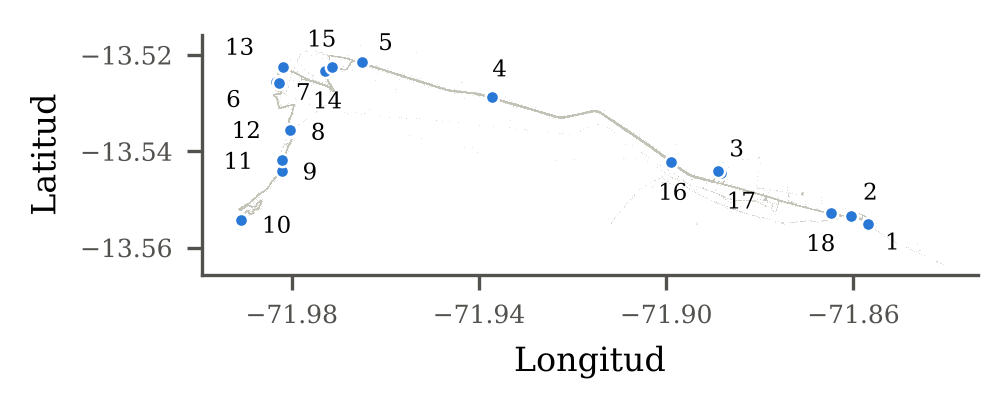

In [10]:
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})
AZUL, ROJO, GRIS = "#2a78d6", "#e34948", "#c3c2b7"

fondo = mon_raw[["latitude", "longitude"]].sample(60000, random_state=0)
fondo = fondo[(fondo.longitude > -72.01) & (fondo.longitude < -71.84) & (fondo.latitude > -13.57) & (fondo.latitude < -13.51)]
fig, ax = plt.subplots(figsize=(3.4, 2.3), dpi=300)
ax.scatter(fondo.longitude, fondo.latitude, s=0.05, c=GRIS, alpha=0.4, linewidths=0, rasterized=True)
off = {1:(4,-6),2:(3,4),3:(2,4),4:(0,5),5:(4,3),6:(-12,-6),7:(4,-4),8:(5,-2),9:(5,-2),10:(5,-3),
       11:(-14,-2),12:(-14,-2),13:(-14,3),14:(-3,-9),15:(-6,5),16:(-3,-9),17:(2,-9),18:(-6,-9)}
for i, (la, lo) in enumerate(pcs, 1):
    ax.scatter(lo, la, s=10, c=AZUL, edgecolors="white", linewidths=0.6, zorder=3)
    ax.annotate(str(i), (lo, la), xytext=off[i], textcoords="offset points", fontsize=5.5)
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.tick_params(labelsize=6)
ax.set_xticks([-71.98, -71.94, -71.90, -71.86])
ax.set_aspect(1 / np.cos(np.radians(13.54)))
fig.tight_layout(); fig.savefig("fig/fig1_ruta.png", bbox_inches="tight", pad_inches=0.02); plt.show()

## 8. Horarios y patrones de retraso (Sección IV-F, Tabla V, Fig. 2, Fig. 3)

In [11]:
h = S[:, 0] / 3600
df = pd.DataFrame({"y": y, "dur": dur, "h": h})[ok]
print("Horarios programados distintos:", sorted(set(dur)))

def hhmm(x):
    return f"{int(x)}:{int(round((x % 1) * 60)):02d}"

tabla_v = (df.groupby("dur")
             .agg(vueltas=("y", "size"), salida_mediana=("h", lambda v: hhmm(np.median(v))),
                  media_min=("y", "mean"), pct_retraso_5=("y", lambda v: (v > 5).mean() * 100),
                  pct_adelanto_1=("y", lambda v: (v < -1).mean() * 100))
             .round(2))
tabla_v

Horarios programados distintos: [np.float64(147.0), np.float64(161.0), np.float64(168.0), np.float64(170.0)]


,vueltas,salida_mediana,media_min,pct_retraso_5,pct_adelanto_1
dur,,,,,
147.0,642,5:50,-5.09,12.31,52.80
161.0,2700,11:02,3.91,25.96,10.26
168.0,178,17:45,3.89,39.33,13.48
170.0,484,17:37,6.00,53.72,8.06


     mean  size
h              
4  -20.04    93
5   -9.57   263
6   -0.16   344
7    1.11   301
8    2.68   268
9    4.31   275
10   4.70   284
11   3.16   279
12   1.43   265
13   3.02   259
14   3.75   278
15   7.23   281
16   9.25   258
17  11.28   249
18   6.82   202
19   0.73   104


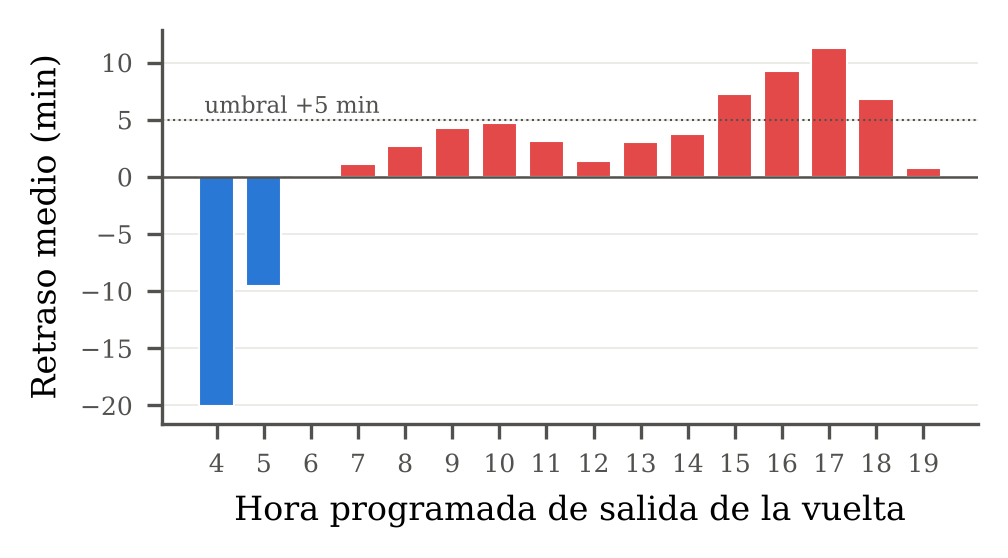

In [12]:
hb = np.floor(h).astype(int)
g = pd.DataFrame({"h": hb[ok], "y": y[ok]}).groupby("h").y.agg(["mean", "size"])
g = g[g["size"] >= 30]
print(g.round(2))

fig, ax = plt.subplots(figsize=(3.4, 1.9), dpi=300)
ax.bar(g.index, g["mean"], color=[AZUL if v < 0 else ROJO for v in g["mean"]], width=0.75, edgecolor="white", linewidth=0.5)
ax.axhline(0, color="#52514e", lw=0.6); ax.axhline(5, color="#52514e", lw=0.5, ls=":")
ax.text(5.6, 5.6, "umbral +5 min", fontsize=5.5, ha="center", color="#52514e")
ax.set_xlabel("Hora programada de salida de la vuelta"); ax.set_ylabel("Retraso medio (min)")
ax.set_xticks(g.index); ax.tick_params(labelsize=6); ax.grid(axis="y", color="#e8e7e3", lw=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("fig/fig2_hora.png"); plt.show()

**Cambio del retraso por tramo.** Para el tramo *j* → *j+1* se calcula `d[j+1] − d[j]`. Un valor positivo indica que el tramo genera retraso; uno negativo, que el bus recupera tiempo.

tramo  media_min  desv_min
  1-2      -0.67      0.57
  2-3       0.25      1.39
  3-4       0.90      1.45
  4-5      -0.16      1.77
  5-6       1.19      2.79
  6-7      -0.60      0.49
  7-8       0.88      1.30
  8-9      -0.47      1.51
 9-10      -0.48      1.82
10-11       0.23      1.60
11-12       0.42      2.33
12-13       0.50      2.22
13-14       2.79      2.24
14-15      -1.96      0.81
15-16       0.91      3.44
16-17       1.04      0.95
17-18      -0.92      1.57

Distancia PC14–PC15: 174 m


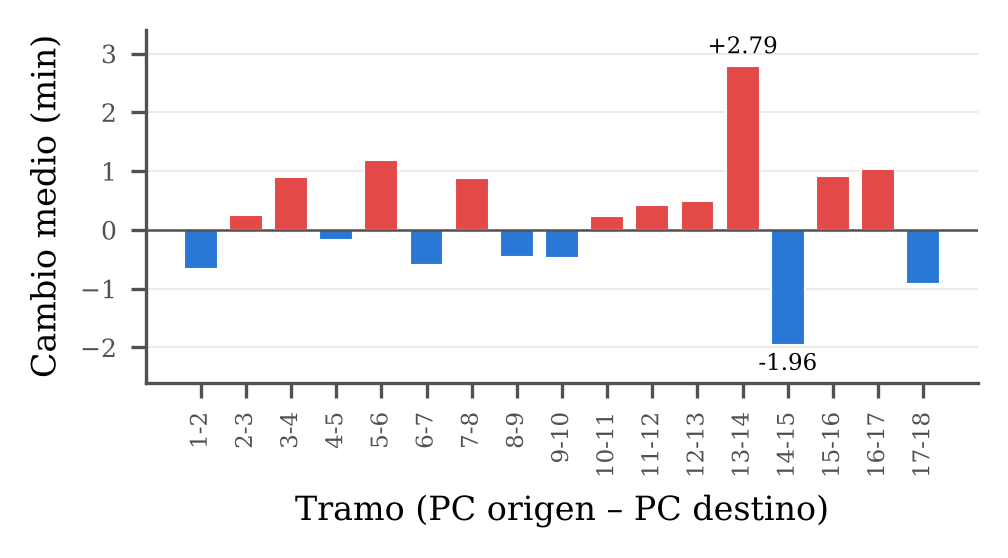

In [13]:
inc = np.diff(D, axis=1)
tramos = pd.DataFrame({"tramo": [f"{j}-{j+1}" for j in range(1, 18)],
                       "media_min": np.nanmean(inc, 0).round(2), "desv_min": np.nanstd(inc, 0).round(2)})
print(tramos.to_string(index=False))
print(f"\nDistancia PC14–PC15: {dist_m(pcs[13], pcs[14]):.0f} m")

fig, ax = plt.subplots(figsize=(3.4, 1.9), dpi=300)
x = np.arange(1, 18); m_inc = np.nanmean(inc, 0)
ax.bar(x, m_inc, color=[AZUL if v < 0 else ROJO for v in m_inc], width=0.75, edgecolor="white", linewidth=0.5)
ax.axhline(0, color="#52514e", lw=0.6)
for xi, v in zip(x, m_inc):
    if abs(v) >= 1.5:
        ax.text(xi, v + (0.12 if v > 0 else -0.12), f"{v:+.2f}", ha="center", va="bottom" if v > 0 else "top", fontsize=5.5)
ax.set_xticks(x); ax.set_xticklabels(tramos.tramo, rotation=90, fontsize=5.5); ax.tick_params(axis="y", labelsize=6)
ax.set_xlabel("Tramo (PC origen – PC destino)"); ax.set_ylabel("Cambio medio (min)")
ax.set_ylim(-2.6, 3.4); ax.grid(axis="y", color="#e8e7e3", lw=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig("fig/fig3_tramos.png"); plt.show()

## 9. Análisis preliminar de viabilidad (Sección V-E, Tabla VIII)

**Objetivo:** comprobar que existe señal predictiva **antes** de proponer el diseño experimental. **No** es el experimento del Entregable 2.

**Configuración:**
- **Partición temporal:** entrenamiento del 06/01 al 23/01 y validación del 24/01 al 27/01. El conjunto de prueba (28/01–01/02) **no se usa** aquí.
- **Sin ajuste de hiperparámetros:** valores razonables por defecto.
- **Variables:**
  - F0 (k = 0): hora programada, día de la semana, horario, vuelta y duración programada.
  - F1 (k > 0): F0 más las desviaciones de los k primeros PC.
- **Imputación:** los faltantes en las desviaciones se imputan con el último valor observado y, si no hay ninguno, con 0. Los modelos lineales usan one-hot para día, horario y vuelta, más estandarización.

In [14]:
fechas = t.date.values
ud = sorted(t.date.unique())
dev, test = ud[:22], ud[22:]
print("Días:", len(ud), "| desarrollo:", dev[0], "a", dev[-1], "| prueba:", test[0], "a", test[-1])
print("Vueltas con y válido — desarrollo:", int((ok & np.isin(fechas, dev)).sum()), "| prueba:", int((ok & np.isin(fechas, test)).sum()))

tr = ok & np.isin(fechas, ud[:18])
va = ok & np.isin(fechas, ud[18:22])
print("Preliminar — entrenamiento:", ud[0], "a", ud[17], f"({tr.sum()} vueltas) | validación:", ud[18], "a", ud[21], f"({va.sum()} vueltas)")

pat = pd.factorize(pd.Series([tuple(r) for r in (S - S[:, [0]])]))[0]   # identificador del horario
dow = pd.to_datetime(t.date).dt.dayofweek.values
cat = np.column_stack([dow, pat, t.lap.values])
oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(cat[tr])

def matrices(k):
    # Devuelve (X_arboles, X_lineal) para el escenario k
    Dk = pd.DataFrame(D[:, :k]).ffill(axis=1).fillna(0).values if k > 0 else np.zeros((len(t), 0))
    X_arb = np.column_stack([Dk, h, dow, pat, t.lap.values, dur])
    X_lin = np.column_stack([Dk, h, h ** 2, dur, oh.transform(cat)])
    return X_arb, X_lin

# Líneas base
media_hora = pd.Series(y[tr]).groupby(hb[tr]).mean()
print(f"\nLínea base media global      : MAE {MAE(y[va], np.full(va.sum(), y[tr].mean())):.2f}")
print(f"Línea base promedio por hora : MAE {MAE(y[va], pd.Series(hb[va]).map(media_hora).fillna(y[tr].mean()).values):.2f}")
mayoritaria = np.bincount(yc[tr]).argmax()
print(f"Línea base clase mayoritaria : F1-macro {f1_score(yc[va], np.full(va.sum(), mayoritaria), average='macro'):.2f}")

Días: 27 | desarrollo: 2025-01-06 a 2025-01-27 | prueba: 2025-01-28 a 2025-02-01
Vueltas con y válido — desarrollo: 3246 | prueba: 758
Preliminar — entrenamiento: 2025-01-06 a 2025-01-23 (2670 vueltas) | validación: 2025-01-24 a 2025-01-27 (576 vueltas)

Línea base media global      : MAE 6.69
Línea base promedio por hora : MAE 5.36
Línea base clase mayoritaria : F1-macro 0.22


In [15]:
filas = []
for k in (0, 4, 8, 12):
    Xa, Xl = matrices(k)
    sc = StandardScaler().fit(Xl[tr])
    fila = {"k": k}
    if k > 0:
        ultimo = pd.DataFrame(D[:, :k]).ffill(axis=1).iloc[:, -1].fillna(0).values
        fila["Persistencia"] = MAE(y[va], ultimo[va])
    fila["Ridge"] = MAE(y[va], Ridge(1.0).fit(sc.transform(Xl[tr]), y[tr]).predict(sc.transform(Xl[va])))
    fila["RF"] = MAE(y[va], RandomForestRegressor(300, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(Xa[tr], y[tr]).predict(Xa[va]))
    fila["XGB"] = MAE(y[va], XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED).fit(Xa[tr], y[tr]).predict(Xa[va]))
    fila["F1 Logística"] = f1_score(yc[va], LogisticRegression(max_iter=2000).fit(sc.transform(Xl[tr]), yc[tr]).predict(sc.transform(Xl[va])), average="macro")
    fila["F1 RF"] = f1_score(yc[va], RandomForestClassifier(300, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(Xa[tr], yc[tr]).predict(Xa[va]), average="macro")
    fila["F1 XGB"] = f1_score(yc[va], XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED).fit(Xa[tr], yc[tr]).predict(Xa[va]), average="macro")
    filas.append(fila)
tabla_viii = pd.DataFrame(filas).set_index("k").round(2)
tabla_viii

,Ridge,RF,XGB,F1 Logística,F1 RF,F1 XGB,Persistencia
k,,,,,,,
0,4.53,3.92,3.86,0.67,0.71,0.69,NaN
4,4.39,3.83,3.73,0.69,0.72,0.72,7.05
8,3.97,3.60,3.62,0.71,0.72,0.74,5.04
12,3.23,3.33,3.14,0.73,0.74,0.75,4.41


## 10. Exploración inicial de variables GPS (Sección V-E)

El paper afirma que agregados GPS simples **no** redujeron el error. Esta celda lo comprueba con la **misma partición y el mismo modelo XGBoost** de la Tabla VIII, comparando F1 frente a F1 + GPS.

**Agregados GPS** de los tramos ya recorridos, usando solo registros entre la salida real y el paso real por PC k, para evitar fuga de información:
- minutos con velocidad ≤ 3 km/h, ponderados por el intervalo hasta el siguiente registro;
- velocidad media ponderada por tiempo;
- desviación estándar de la velocidad.

In [16]:
gps_vel = {k: (v.t_seg.values, v.speed.values) for k, v in mon.groupby(["vehicle_id_id", "date"])}

def agregados_gps(i, k):
    key = (t.vehicle_id_id.iat[i], t.date.iat[i])
    if key not in gps_vel:
        return [np.nan] * 3
    ss, sp = gps_vel[key]
    sel = (ss >= E[i, 0]) & (ss <= E[i, k - 1])
    if sel.sum() < 3:
        return [np.nan] * 3
    s2, v2 = ss[sel], sp[sel]
    dt = np.diff(s2, append=s2[-1])
    return [dt[v2 <= 3].sum() / 60, np.average(v2, weights=np.maximum(dt, 1)), v2.std()]

filas = []
for k in (4, 8, 12):
    Xa, _ = matrices(k)
    G = np.array([agregados_gps(i, k) for i in range(len(t))])
    Xg = np.column_stack([Xa, G])
    mae_f1 = MAE(y[va], XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED).fit(Xa[tr], y[tr]).predict(Xa[va]))
    mae_f2 = MAE(y[va], XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED).fit(Xg[tr], y[tr]).predict(Xg[va]))
    filas.append({"k": k, "MAE F1": mae_f1, "MAE F1+GPS": mae_f2,
                  "corr(min detenido, y)": pd.Series(G[ok, 0]).corr(pd.Series(y[ok]))})
pd.DataFrame(filas).set_index("k").round(3)

,MAE F1,MAE F1+GPS,"corr(min detenido, y)"
k,,,
4,3.725,3.727,0.013
8,3.620,3.593,0.032
12,3.143,3.099,0.042
